## Import the required packages

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import joblib

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sklearn

print(sklearn.__version__)

1.7.2


## Load the dataset

In [4]:
df = pd.read_csv(r"C:\Users\User\Downloads\computer_prices_all.csv")

df.head()

,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,...,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,...,2560x1440,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,...,1920x1080,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,...,3440x1440,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99
3,3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,...,3440x1440,120,0,0,650,Wi-Fi 6,5.2,6.00,36,1331.99
4,4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,...,2560x1600,90,80,90,0,Wi-Fi 6,5.2,1.50,12,2681.99


In [5]:
df.shape

(100000, 34)

In [6]:
df.columns

Index(['ID', 'device_type', 'brand', 'model', 'release_year', 'os',
       'form_factor', 'cpu_brand', 'cpu_model', 'cpu_tier', 'cpu_cores',
       'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_brand',
       'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type',
       'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in',
       'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts',
       'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price'],
      dtype='str')

In [7]:
df.dtypes

ID                       int64
device_type                str
brand                      str
model                      str
release_year             int64
os                         str
form_factor                str
cpu_brand                  str
cpu_model                  str
cpu_tier                 int64
cpu_cores                int64
cpu_threads              int64
cpu_base_ghz           float64
cpu_boost_ghz          float64
gpu_brand                  str
gpu_model                  str
gpu_tier                 int64
vram_gb                  int64
ram_gb                   int64
storage_type               str
storage_gb               int64
storage_drive_count      int64
display_type               str
display_size_in        float64
resolution                 str
refresh_hz               int64
battery_wh               int64
charger_watts            int64
psu_watts                int64
wifi                       str
bluetooth              float64
weight_kg              float64
warranty

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   100000 non-null  int64  
 1   device_type          100000 non-null  str    
 2   brand                100000 non-null  str    
 3   model                100000 non-null  str    
 4   release_year         100000 non-null  int64  
 5   os                   100000 non-null  str    
 6   form_factor          100000 non-null  str    
 7   cpu_brand            100000 non-null  str    
 8   cpu_model            100000 non-null  str    
 9   cpu_tier             100000 non-null  int64  
 10  cpu_cores            100000 non-null  int64  
 11  cpu_threads          100000 non-null  int64  
 12  cpu_base_ghz         100000 non-null  float64
 13  cpu_boost_ghz        100000 non-null  float64
 14  gpu_brand            100000 non-null  str    
 15  gpu_model            100000 n

In [9]:
df.describe()

,ID,release_year,cpu_tier,cpu_cores,cpu_threads,cpu_base_ghz,cpu_boost_ghz,gpu_tier,vram_gb,ram_gb,...,storage_drive_count,display_size_in,refresh_hz,battery_wh,charger_watts,psu_watts,bluetooth,weight_kg,warranty_months,price
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000
mean,49999.500000,2022.320850,3.153490,10.515740,19.372700,2.591322,3.531310,2.991350,6.152180,39.706400,...,1.524980,20.126655,98.464860,41.813470,61.383450,272.520500,5.084764,4.289699,22.20036,1928.764220
std,28867.657797,2.025761,1.373175,5.044092,9.718426,0.336435,0.350024,1.459643,3.964926,31.902684,...,0.797284,6.709577,43.301652,35.868841,62.795034,354.686355,0.245977,3.814628,10.23190,580.492689
min,0.000000,2018.000000,1.000000,4.000000,4.000000,2.000000,2.800000,1.000000,0.000000,8.000000,...,1.000000,13.300000,60.000000,0.000000,0.000000,0.000000,4.200000,0.920000,12.00000,372.990000
25%,24999.750000,2021.000000,2.000000,6.000000,12.000000,2.400000,3.300000,2.000000,4.000000,16.000000,...,1.000000,14.000000,60.000000,0.000000,0.000000,0.000000,5.000000,1.500000,12.00000,1503.990000
50%,49999.500000,2023.000000,3.000000,8.000000,16.000000,2.600000,3.500000,3.000000,6.000000,32.000000,...,1.000000,16.000000,90.000000,56.000000,65.000000,0.000000,5.100000,2.000000,24.00000,1863.990000
75%,74999.250000,2024.000000,4.000000,14.000000,24.000000,2.800000,3.800000,4.000000,8.000000,64.000000,...,2.000000,27.000000,120.000000,70.000000,90.000000,650.000000,5.200000,7.000000,24.00000,2287.990000
max,99999.000000,2025.000000,6.000000,28.000000,56.000000,3.400000,4.500000,6.000000,16.000000,144.000000,...,4.000000,34.000000,240.000000,99.000000,240.000000,1200.000000,5.300000,16.000000,48.00000,10984.990000


In [10]:
## Check categorical columns:
print(df.select_dtypes(include='object').columns)

Index(['device_type', 'brand', 'model', 'os', 'form_factor', 'cpu_brand',
       'cpu_model', 'gpu_brand', 'gpu_model', 'storage_type', 'display_type',
       'resolution', 'wifi'],
      dtype='str')


In [11]:
## Check numerical columns:
print(df.select_dtypes(include=np.number).columns)

Index(['ID', 'release_year', 'cpu_tier', 'cpu_cores', 'cpu_threads',
       'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_tier', 'vram_gb', 'ram_gb',
       'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz',
       'battery_wh', 'charger_watts', 'psu_watts', 'bluetooth', 'weight_kg',
       'warranty_months', 'price'],
      dtype='str')


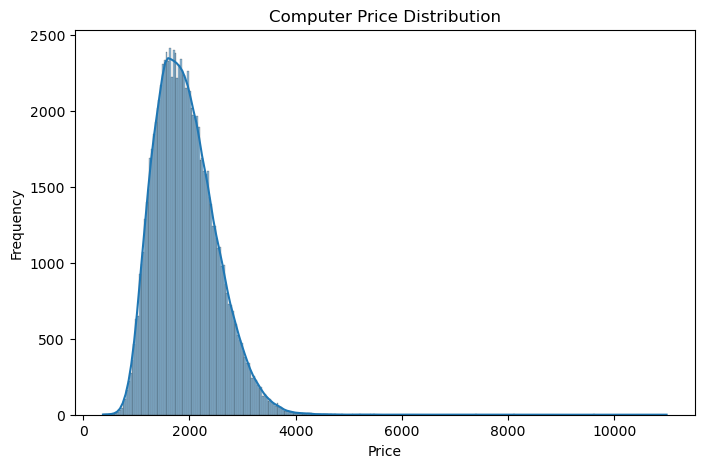

In [12]:
## Target variable distribution
plt.figure(figsize=(8,5))

sns.histplot(df['price'], kde=True)

plt.title('Computer Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

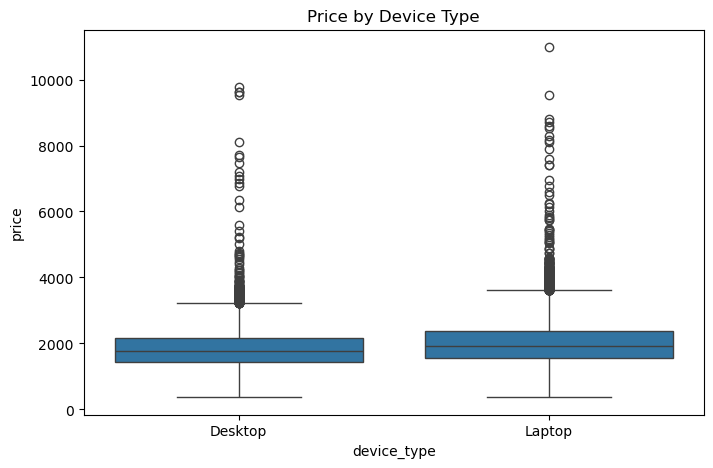

In [13]:
# Price distribution by device type
plt.figure(figsize=(8,5))

sns.boxplot(x='device_type', y='price', data=df)

plt.title('Price by Device Type')
plt.show()

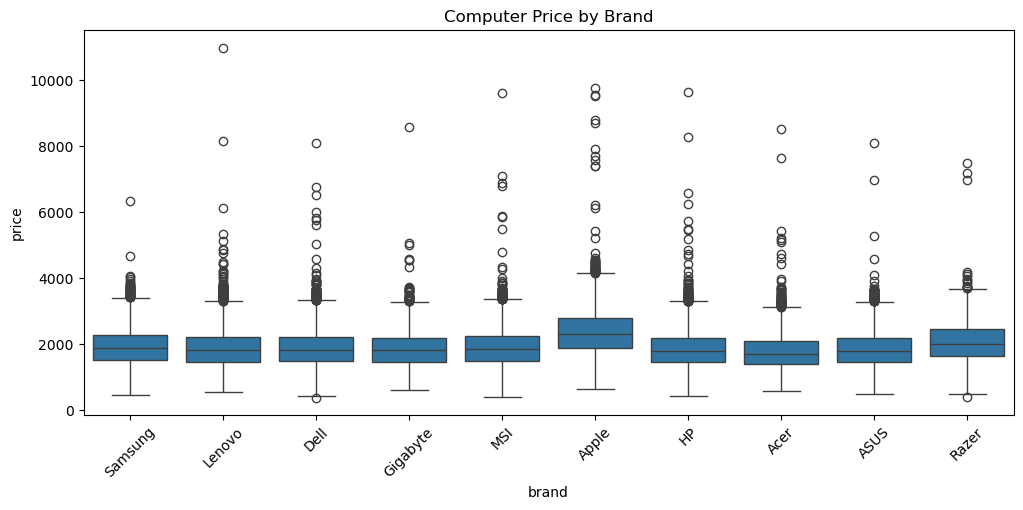

In [14]:
## Price by brand
plt.figure(figsize=(12,5))

sns.boxplot(x='brand', y='price', data=df)

plt.xticks(rotation=45)
plt.title('Computer Price by Brand')

plt.show()

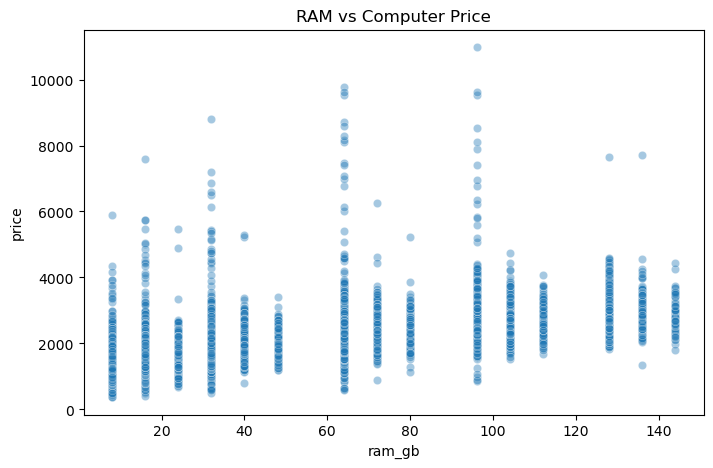

In [15]:
# RAM vs Price
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='ram_gb',
    y='price',
    data=df,
    alpha=0.4
)

plt.title('RAM vs Computer Price')
plt.show()

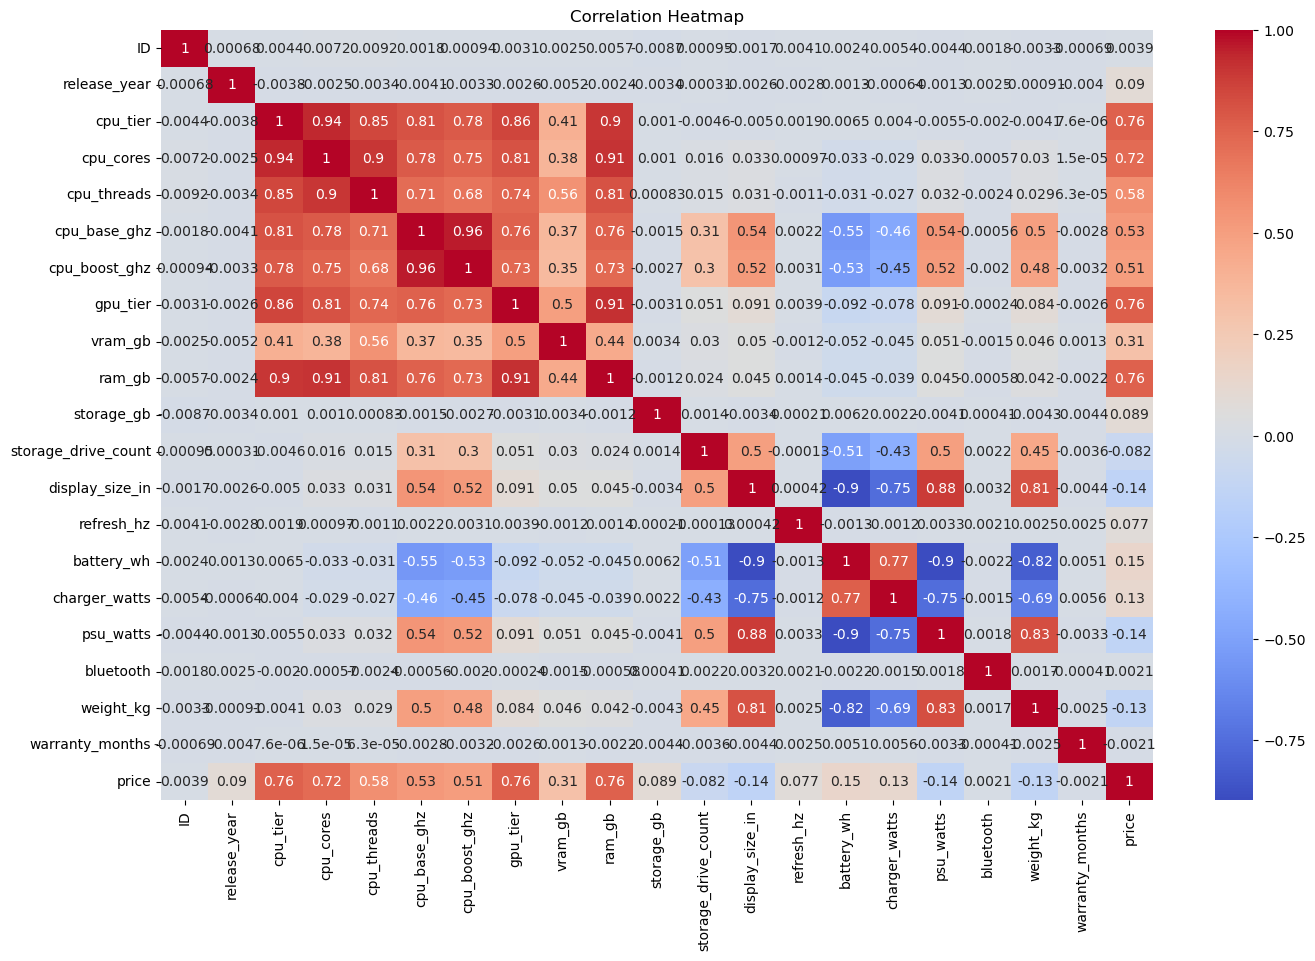

In [16]:
## Correlation heatmap
plt.figure(figsize=(16,10))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=True
)

plt.title('Correlation Heatmap')
plt.show()

In [17]:
## Check and handle missing values
# Check missing values
print(df.isnull().sum())

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())

ID                     0
device_type            0
brand                  0
model                  0
release_year           0
os                     0
form_factor            0
cpu_brand              0
cpu_model              0
cpu_tier               0
cpu_cores              0
cpu_threads            0
cpu_base_ghz           0
cpu_boost_ghz          0
gpu_brand              0
gpu_model              0
gpu_tier               0
vram_gb                0
ram_gb                 0
storage_type           0
storage_gb             0
storage_drive_count    0
display_type           0
display_size_in        0
resolution             0
refresh_hz             0
battery_wh             0
charger_watts          0
psu_watts              0
wifi                   0
bluetooth              0
weight_kg              0
warranty_months        0
price                  0
dtype: int64
Total Missing Values: 0


In [18]:
# Missing values percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

ID                     0.0
device_type            0.0
brand                  0.0
model                  0.0
release_year           0.0
os                     0.0
form_factor            0.0
cpu_brand              0.0
cpu_model              0.0
cpu_tier               0.0
cpu_cores              0.0
cpu_threads            0.0
cpu_base_ghz           0.0
cpu_boost_ghz          0.0
gpu_brand              0.0
gpu_model              0.0
gpu_tier               0.0
vram_gb                0.0
ram_gb                 0.0
storage_type           0.0
storage_gb             0.0
storage_drive_count    0.0
display_type           0.0
display_size_in        0.0
resolution             0.0
refresh_hz             0.0
battery_wh             0.0
charger_watts          0.0
psu_watts              0.0
wifi                   0.0
bluetooth              0.0
weight_kg              0.0
warranty_months        0.0
price                  0.0
dtype: float64


In [19]:
## Check and handle duplicate records
# Check duplicates
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate Records: 0
Shape after removing duplicates: (100000, 34)


## Feature selection and preprocessing
This step is important for improving model generalization.

We will remove:
- ID: Unique identifier, not a meaningful computer specification.
- model: Contains 99,036 unique values.
- cpu_model: Contains 26,971 unique values.
These high-cardinality columns can create excessive one-hot encoded features and increase overfitting risk. We retain cpu_brand, cpu_tier, gpu_model and other useful specifications.
    

In [20]:
# Remove unnecessary columns
df = df.drop(
    columns=['ID', 'model', 'cpu_model'],
    errors='ignore'
)

print(df.shape)

(100000, 31)


In [21]:
# Separate features and target variable
X = df.drop('price', axis=1)

y = df['price']

print("Independent variables:", X.shape)
print("Dependent variable:", y.shape)

Independent variables: (100000, 30)
Dependent variable: (100000,)


In [22]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['release_year', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'bluetooth', 'weight_kg', 'warranty_months']
Categorical Features: ['device_type', 'brand', 'os', 'form_factor', 'cpu_brand', 'gpu_brand', 'gpu_model', 'storage_type', 'display_type', 'resolution', 'wifi']


Create preprocessing pipelines

#### For numerical data:
- Fill missing values using median.
- Apply standard scaling.
#### For categorical data:
- Fill missing values using most frequent values.
- Apply One-Hot Encoding.

In [23]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [24]:
## Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80000, 30)
X_test: (20000, 30)
y_train: (80000,)
y_test: (20000,)


## Build Multiple Linear Regression
Multiple Linear Regression predicts a target using multiple independent variables.

Shows an interactive scatterplot where draggable observed points update the least-squares line of best fit. Observed points, fitted predictions, and vertical residual gaps remain visible together while generated datasets vary.

In [25]:
# Create model
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train model
linear_model.fit(X_train, y_train)

# Predictions
linear_pred = linear_model.predict(X_test)

print("Multiple Linear Regression completed")

Multiple Linear Regression completed


## Build Polynomial Regression
Polynomial Regression helps identify nonlinear relationships between input variables and price.

We will use degree 2, which includes squared terms and pairwise interactions of numerical features.

Categorical variables will be one-hot encoded separately.

In [26]:
# Numerical preprocessing for polynomial regression
poly_numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler1', StandardScaler()),
    ('poly', PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ('scaler2', StandardScaler())
])

# Categorical preprocessing
poly_categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
poly_preprocessor = ColumnTransformer([
    ('num', poly_numeric_pipeline, numeric_features),
    ('cat', poly_categorical_pipeline, categorical_features)
])

# Create polynomial regression model
polynomial_model = Pipeline([
    ('preprocessor', poly_preprocessor),
    ('model', LinearRegression())
])

# Train
polynomial_model.fit(X_train, y_train)

# Prediction
poly_pred = polynomial_model.predict(X_test)

print("Polynomial Regression completed")

Polynomial Regression completed


## Build Decision Tree Regression
Decision Tree Regression can learn nonlinear relationships and interactions between computer specifications.

In [33]:
# Decision tree preprocessing
tree_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

# Create Decision Tree
tree_model = Pipeline([
    ('preprocessor', tree_preprocessor),

    ('model', DecisionTreeRegressor(
        random_state=42
    ))
])

# Train model
tree_model.fit(X_train, y_train)

# Prediction
tree_pred = tree_model.predict(X_test)

print("Decision Tree Regression completed")

Decision Tree Regression completed


In [34]:
## Hyperparameter tuning using RandomizedSearchCV
# Hyperparameter search space
param_grid = {
    'model__max_depth': [8, 10, 12, 15, 20, None],

    'model__min_samples_split': [2, 5, 10, 20],

    'model__min_samples_leaf': [1, 2, 5, 10],

    'model__max_features': [None, 'sqrt', 0.8]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=tree_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring='neg_mean_absolute_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit search
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("Best CV MAE:", -random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters:
{'model__min_samples_split': 5, 'model__min_samples_leaf': 10, 'model__max_features': None, 'model__max_depth': 15}
Best CV MAE: 187.81160974306513


In [35]:
best_tree_model = random_search.best_estimator_

tree_tuned_pred = best_tree_model.predict(X_test)

print("Tuned Decision Tree completed")

Tuned Decision Tree completed


## Cross-validation
Cross-validation helps evaluate how consistently a model performs across different training and validation subsets.

We will use 3-fold cross-validation for all three algorithms.

In [36]:
kf = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

models = {
    'Multiple Linear Regression': linear_model,

    'Polynomial Regression': polynomial_model,

    'Decision Tree': best_tree_model
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring='r2',
        n_jobs=-1
    )

    print("\n", name)

    print("CV Scores:", scores)

    print("Mean CV R2:", scores.mean())

    print("Standard Deviation:", scores.std())


 Multiple Linear Regression
CV Scores: [0.84583074 0.84702005 0.85336802]
Mean CV R2: 0.8487396049420722
Standard Deviation: 0.0033086068731565835

 Polynomial Regression
CV Scores: [0.85187022 0.85311828 0.86106683]
Mean CV R2: 0.8553517786746948
Standard Deviation: 0.004073146520066838

 Decision Tree
CV Scores: [0.77835419 0.77447134 0.78319657]
Mean CV R2: 0.7786740330404407
Standard Deviation: 0.0035692341782602886


In [37]:
# Evaluation function

def evaluate_model(y_test, y_pred):

    r2 = r2_score(y_test, y_pred)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    return r2, mae, mse, rmse

In [38]:
results = []

predictions = {
    'Multiple Linear Regression': linear_pred,

    'Polynomial Regression': poly_pred,

    'Decision Tree': tree_tuned_pred
}

for name, pred in predictions.items():

    r2, mae, mse, rmse = evaluate_model(
        y_test,
        pred
    )

    results.append({
        'Algorithm': name,
        'R2 Score': r2,
        'R2 Percentage': r2 * 100,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='R2 Score',
        ascending=False
    )
)

,Algorithm,R2 Score,R2 Percentage,MAE,MSE,RMSE
1,Polynomial Regression,0.882544,88.254409,138.029686,38785.608677,196.940622
0,Multiple Linear Regression,0.875395,87.539504,143.165870,41146.327657,202.845576
2,Decision Tree,0.810883,81.088274,181.612679,62449.201554,249.898382


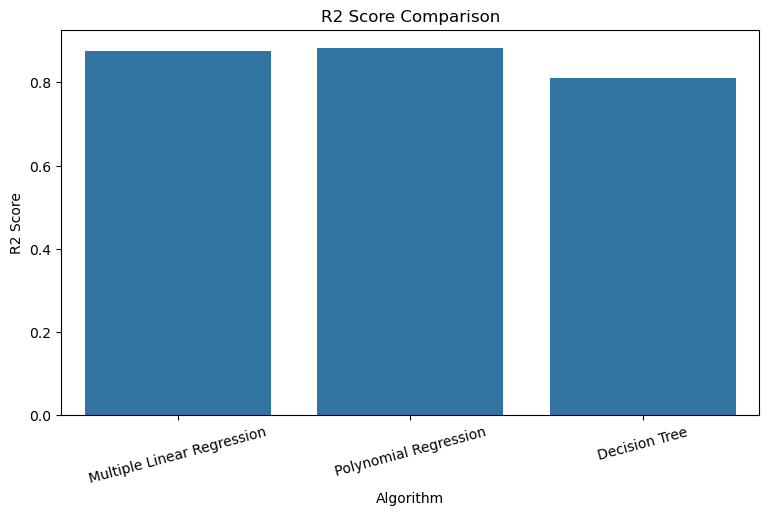

In [39]:
## R² score comparison
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='R2 Score'
)

plt.title('R2 Score Comparison')

plt.xticks(rotation=15)

plt.show()

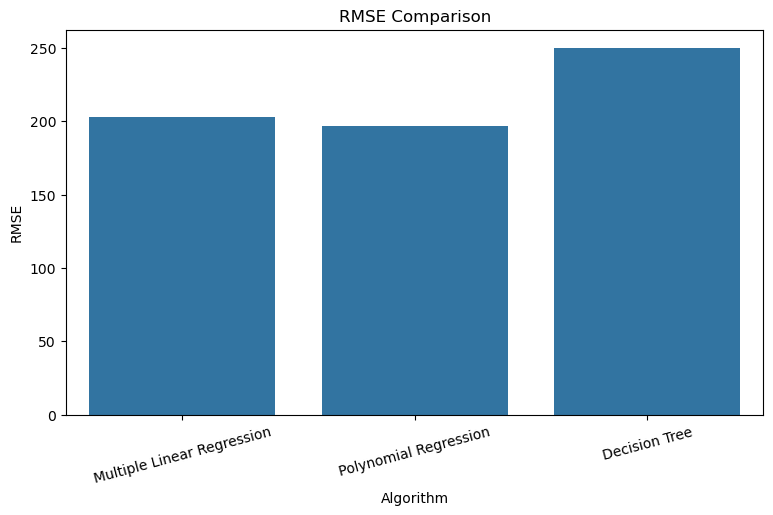

In [40]:
## RMSE comparison
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='RMSE'
)

plt.title('RMSE Comparison')

plt.xticks(rotation=15)

plt.show()

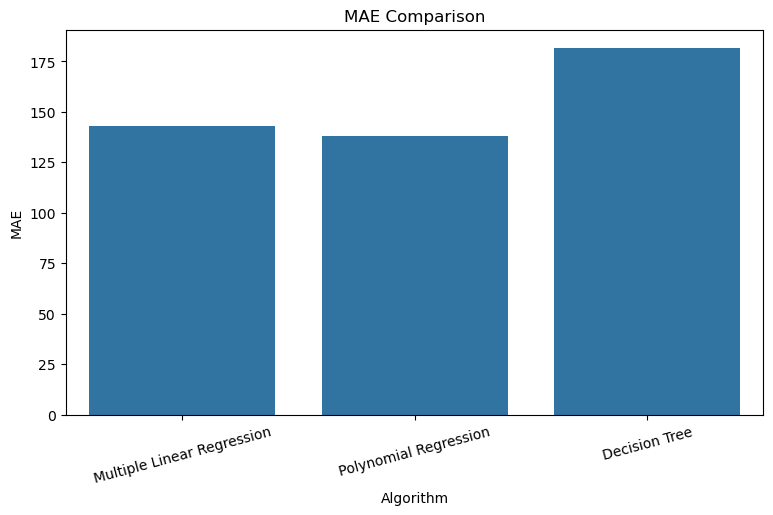

In [41]:
# MAE comparison
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='MAE'
)

plt.title('MAE Comparison')

plt.xticks(rotation=15)

plt.show()

In [42]:
## Identify the best-performing algorithm select the model with the highest test R² score.
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(),
    'Algorithm'
]

print("Best Performing Algorithm:", best_model_name)

best_r2 = results_df['R2 Score'].max()

print("Best R2 Score:", best_r2)

print("Performance Percentage:", best_r2 * 100)

Best Performing Algorithm: Polynomial Regression
Best R2 Score: 0.8825440888128784
Performance Percentage: 88.25440888128784


In [43]:
best_models = {
    'Multiple Linear Regression': linear_model,

    'Polynomial Regression': polynomial_model,

    'Decision Tree': best_tree_model
}

best_model = best_models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Polynomial Regression


In [44]:
best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': best_predictions
})

display(comparison.head(15))

,Actual Price,Predicted Price
0,1736.99,1998.544558
1,1459.99,1564.354062
2,2008.99,1995.684804
3,2789.99,2446.700020
4,1421.99,1425.654556
5,1139.99,946.976949
6,2114.99,2160.549909
7,2758.99,2868.745440
8,1246.99,1295.442940
9,1717.99,2055.070165


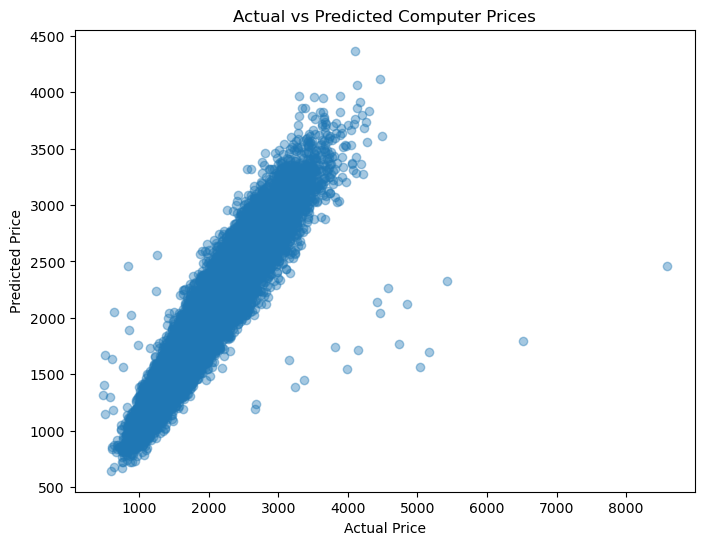

In [45]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.4
)

plt.xlabel('Actual Price')

plt.ylabel('Predicted Price')

plt.title('Actual vs Predicted Computer Prices')

plt.show()

In [46]:
## Save the best model
joblib.dump(
    best_model,
    'best_computer_price_model.pkl'
)

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
## Test the model with new input
sample_input = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = loaded_model.predict(sample_input)[0]

print("Actual Computer Price:", actual_price)

print("Predicted Computer Price:", predicted_price)

print(
    "Absolute Error:",
    abs(actual_price - predicted_price)
)